<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_9/dataset_pbl/tugas_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laporan Jobsheet 09: Tugas 1 - Klasifikasi k-NN & Seleksi Fitur
## Data Preparation & Preprocessing

Tahapan persiapan data dari dataset *Sleep Health and Lifestyle*: load data, penanganan missing values, ekstraksi fitur, encoding kategorikal, dan pembagian dataset menjadi data latih dan uji (80:20) dengan stratifikasi target *Sleep Disorder*.


In [1]:
# Langkah 1 - Load Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

# Menampilkan 5 data teratas
df.head()


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [2]:
# Langkah 2 - Preprocessing

# 2a. Penanganan nilai label 'None' (pandas membacanya sebagai NaN secara default)
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')

# 2b. Drop kolom 'Person ID' yang tidak digunakan untuk permodelan
df = df.drop(columns=['Person ID'])

# 2c. Memecah fitur 'Blood Pressure' menjadi 'Systolic_BP' dan 'Diastolic_BP'
df[['Systolic_BP', 'Diastolic_BP']] = df['Blood Pressure'].str.split('/', expand=True).astype(int)
df = df.drop(columns=['Blood Pressure'])

# Standarisasi nilai 'Normal Weight' menjadi 'Normal' pada kolom BMI Category
df['BMI Category'] = df['BMI Category'].replace({'Normal Weight': 'Normal'})

# 2d. Inspeksi Data
print("Distribusi Target (Sleep Disorder):")
print(df['Sleep Disorder'].value_counts())
print('\nInformasi Dataset:')
print(df.info())
print('\nStatistik Deskriptif:')
display(df.describe())


Distribusi Target (Sleep Disorder):
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   374 non-null    object 
 1   Age                      374 non-null    int64  
 2   Occupation               374 non-null    object 
 3   Sleep Duration           374 non-null    float64
 4   Quality of Sleep         374 non-null    int64  
 5   Physical Activity Level  374 non-null    int64  
 6   Stress Level             374 non-null    int64  
 7   BMI Category             374 non-null    object 
 8   Heart Rate               374 non-null    int64  
 9   Daily Steps              374 non-null    int64  
 10  Sleep Disorder           374 non-null    object 
 11  Systolic_BP              374 non-n

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic_BP,Diastolic_BP
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920,128.553476,84.649733
std,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679,7.748118,6.161611
min,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000,115.000000,75.000000
25%,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000,125.000000,80.000000
50%,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000,130.000000,85.000000
75%,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000,135.000000,90.000000
max,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000,142.000000,95.000000


In [3]:
# 2e. Encoding Fitur Kategorikal dan Label Target
from sklearn.preprocessing import LabelEncoder

le_gender = LabelEncoder()
le_occ = LabelEncoder()
le_bmi = LabelEncoder()
le_target = LabelEncoder()

df_encoded = df.copy()
df_encoded['Gender'] = le_gender.fit_transform(df_encoded['Gender'])
df_encoded['Occupation'] = le_occ.fit_transform(df_encoded['Occupation'])
df_encoded['BMI Category'] = le_bmi.fit_transform(df_encoded['BMI Category'])
df_encoded['Sleep Disorder'] = le_target.fit_transform(df_encoded['Sleep Disorder'])

print("Mapping Label Target:")
for idx, label in enumerate(le_target.classes_):
    print(f"{label} -> {idx}")

df_encoded.head()


Mapping Label Target:
Insomnia -> 0
None -> 1
Sleep Apnea -> 2


,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
0,1,27,9,6.1,6,42,6,2,77,4200,1,126,83
1,1,28,1,6.2,6,60,8,0,75,10000,1,125,80
2,1,28,1,6.2,6,60,8,0,75,10000,1,125,80
3,1,28,6,5.9,4,30,8,1,85,3000,2,140,90
4,1,28,6,5.9,4,30,8,1,85,3000,2,140,90


In [4]:
# Langkah 3 - Pemisahan Fitur & Target serta Data Splitting
from sklearn.model_selection import train_test_split

# Memisahkan Fitur (X) dan Target (y)
X = df_encoded.drop(columns=['Sleep Disorder'])
y = df_encoded['Sleep Disorder']

# Split Data (80% Train, 20% Test) dengan stratifikasi agar proporsi kelas seimbang
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Jumlah sampel Train : {X_train.shape[0]}")
print(f"Jumlah sampel Test  : {X_test.shape[0]}")


Jumlah sampel Train : 299
Jumlah sampel Test  : 75


# Tugas 1: Klasifikasi k-NN, Seleksi Fitur Optimal, & Analisis Nilai $k$

Berdasarkan instruksi modul JS09 Tugas 1 yang disesuaikan dengan dataset Sleep Health and Lifestyle:
1. **Soal 1:** Buatlah model klasifikasi dengan menggunakan $k$-NN untuk mengklasifikasikan kategori gangguan tidur (*Sleep Disorder*).
2. **Soal 2:** Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?
3. **Soal 3:** Berdasarkan fitur yang telah dipilih pada soal nomor 2, berapa nilai $k$ yang terbaik? Lampirkan grafik analisis dan alasan Anda.


In [5]:
# =========================================================
# SOAL 1: Model Klasifikasi Baseline k-NN
# =========================================================
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Standarisasi fitur agar memiliki rata-rata 0 dan variansi 1
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Inisialisasi model k-NN baseline (default k=5) dengan seluruh fitur
knn_baseline = KNeighborsClassifier(n_neighbors=5)
knn_baseline.fit(X_train_scaled, y_train)

y_pred_train_base = knn_baseline.predict(X_train_scaled)
y_pred_test_base = knn_baseline.predict(X_test_scaled)

print("=== EVALUASI BASELINE k-NN (k=5, 12 Fitur) ===")
print(f"Akurasi Data Train : {accuracy_score(y_train, y_pred_train_base):.4f}")
print(f"Akurasi Data Test  : {accuracy_score(y_test, y_pred_test_base):.4f}")


=== EVALUASI BASELINE k-NN (k=5, 12 Fitur) ===
Akurasi Data Train : 0.8896
Akurasi Data Test  : 0.9467


In [6]:
# =========================================================
# SOAL 2: Percobaan Seleksi Fitur Paling Optimal
# =========================================================
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import cross_val_score

feature_names = list(X.columns)

# Mengukur signifikansi fitur terhadap target menggunakan ANOVA F-value
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_train_scaled, y_train)

f_scores = pd.DataFrame({
    'Fitur': feature_names,
    'F_Score': selector.scores_
}).sort_values(by='F_Score', ascending=False).reset_index(drop=True)

print("Ranking Kekuatan Pengaruh Fitur (ANOVA F-Score):")
display(f_scores)

# Menguji performa k-NN dengan subset fitur terbaik (Top-1 s/d Top-12)
k_feat_experiments = []
for k in range(1, len(feature_names) + 1):
    selected = f_scores['Fitur'].head(k).tolist()

    X_tr_sub = scaler.fit_transform(X_train[selected])
    X_te_sub = scaler.transform(X_test[selected])

    cv = cross_val_score(KNeighborsClassifier(n_neighbors=5), X_tr_sub, y_train, cv=5).mean()

    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_tr_sub, y_train)
    test_score = model.score(X_te_sub, y_test)

    k_feat_experiments.append({
        'Jumlah_Fitur': k,
        'Daftar_Fitur': selected,
        'CV_Accuracy': cv,
        'Test_Accuracy': test_score
    })

df_feat_results = pd.DataFrame(k_feat_experiments)
display(df_feat_results[['Jumlah_Fitur', 'CV_Accuracy', 'Test_Accuracy']])

# Konfigurasi fitur terbaik berdasarkan CV Accuracy tertinggi
best_subset = df_feat_results.sort_values(by=['CV_Accuracy', 'Test_Accuracy'], ascending=False).iloc[0]
optimal_features = best_subset['Daftar_Fitur']

print(f"\n>>> FITUR TERBAIK YANG DIGUNAKAN ({len(optimal_features)} Fitur): {optimal_features}")
print(f"Cross-Validation Accuracy: {best_subset['CV_Accuracy']:.4f}")
print(f"Testing Accuracy: {best_subset['Test_Accuracy']:.4f}")


Ranking Kekuatan Pengaruh Fitur (ANOVA F-Score):


,Fitur,F_Score
0,BMI Category,230.844461
1,Diastolic_BP,184.343864
2,Systolic_BP,150.374902
3,Occupation,84.492319
4,Age,41.989462
5,Physical Activity Level,33.300814
6,Sleep Duration,27.389586
7,Heart Rate,25.960690
8,Gender,24.088446
9,Quality of Sleep,22.364485


,Jumlah_Fitur,CV_Accuracy,Test_Accuracy
0,1,0.715706,0.746667
1,2,0.846215,0.920000
2,3,0.882881,0.946667
3,4,0.882825,0.933333
4,5,0.866158,0.933333
5,6,0.869492,0.920000
6,7,0.856158,0.880000
7,8,0.856102,0.906667
8,9,0.862825,0.920000
9,10,0.862825,0.946667



>>> FITUR TERBAIK YANG DIGUNAKAN (3 Fitur): ['BMI Category', 'Diastolic_BP', 'Systolic_BP']
Cross-Validation Accuracy: 0.8829
Testing Accuracy: 0.9467


Nilai k terbaik terpilih: k = 3
5-Fold CV Accuracy pada k=3 : 0.8829
Akurasi Train pada k=3      : 0.8963
Akurasi Test pada k=3       : 0.9600


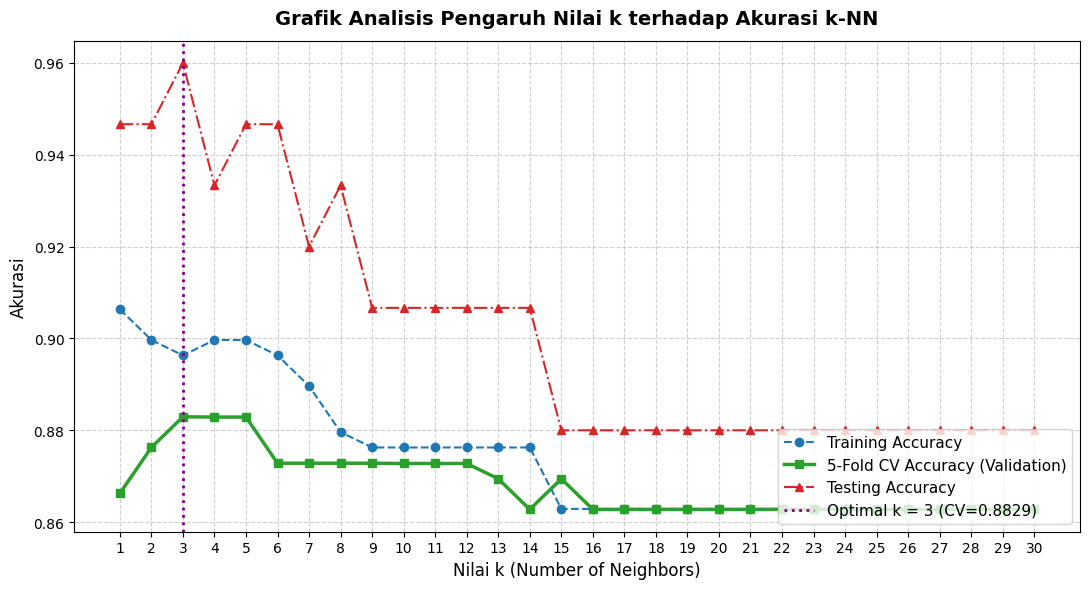

In [7]:
# =========================================================
# SOAL 3: Analisis dan Penentuan Nilai k Terbaik
# =========================================================

# Menyiapkan dataset hanya dengan fitur optimal yang terpilih
X_train_opt = X_train[optimal_features]
X_test_opt = X_test[optimal_features]

scaler_opt = StandardScaler()
X_tr_opt_sc = scaler_opt.fit_transform(X_train_opt)
X_te_opt_sc = scaler_opt.transform(X_test_opt)

# Eksperimen tuning nilai k dari 1 hingga 30
k_range = list(range(1, 31))
train_scores = []
cv_scores = []
test_scores = []

for k in k_range:
    clf = KNeighborsClassifier(n_neighbors=k)
    cv = cross_val_score(clf, X_tr_opt_sc, y_train, cv=5).mean()
    clf.fit(X_tr_opt_sc, y_train)

    train_scores.append(clf.score(X_tr_opt_sc, y_train))
    cv_scores.append(cv)
    test_scores.append(clf.score(X_te_opt_sc, y_test))

# Menemukan k dengan skor validasi silang tertinggi
best_k_idx = int(np.argmax(cv_scores))
best_k = k_range[best_k_idx]

print(f"Nilai k terbaik terpilih: k = {best_k}")
print(f"5-Fold CV Accuracy pada k={best_k} : {cv_scores[best_k_idx]:.4f}")
print(f"Akurasi Train pada k={best_k}      : {train_scores[best_k_idx]:.4f}")
print(f"Akurasi Test pada k={best_k}       : {test_scores[best_k_idx]:.4f}")

# Visualisasi Grafik Analisis Nilai k
plt.figure(figsize=(11, 6))
plt.plot(k_range, train_scores, marker='o', label='Training Accuracy', color='#1f77b4', linestyle='--')
plt.plot(k_range, cv_scores, marker='s', label='5-Fold CV Accuracy (Validation)', color='#2ca02c', linewidth=2.5)
plt.plot(k_range, test_scores, marker='^', label='Testing Accuracy', color='#d62728', linestyle='-.')

plt.axvline(x=best_k, color='purple', linestyle=':', linewidth=2, label=f'Optimal k = {best_k} (CV={cv_scores[best_k_idx]:.4f})')
plt.title('Grafik Analisis Pengaruh Nilai k terhadap Akurasi k-NN', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Nilai k (Number of Neighbors)', fontsize=12)
plt.ylabel('Akurasi', fontsize=12)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()


=== CLASSIFICATION REPORT FINAL k-NN (k = 3) ===
              precision    recall  f1-score   support

    Insomnia       0.93      0.93      0.93        15
        None       0.98      0.98      0.98        44
 Sleep Apnea       0.94      0.94      0.94        16

    accuracy                           0.96        75
   macro avg       0.95      0.95      0.95        75
weighted avg       0.96      0.96      0.96        75



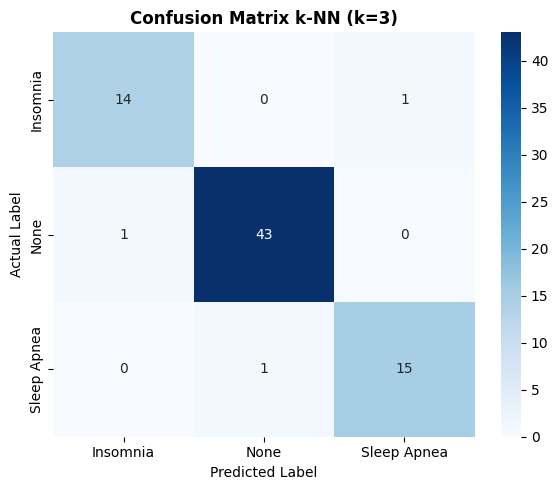

In [8]:
# Evaluasi Final Model k-NN dengan Fitur Optimal dan k Terbaik
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_tr_opt_sc, y_train)

y_pred_final = final_model.predict(X_te_opt_sc)

print(f"=== CLASSIFICATION REPORT FINAL k-NN (k = {best_k}) ===")
print(classification_report(y_test, y_pred_final, target_names=le_target.classes_))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le_target.classes_, yticklabels=le_target.classes_)
plt.title(f'Confusion Matrix k-NN (k={best_k})', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()
